# 01 - Exploratory data analysis

Goal: understand the target, the draft curve and the window features before modelling.

**Only the training classes (drafted 2000-2016) are used here.** The test classes
(2017-2022) stay unseen until the final evaluation, so no modelling decision is
informed by them.

Each section ends with a *What to look for* note.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_features as bf  # reuse the exact feature formulas

PROC = ROOT / "data" / "processed"
TEST_FROM = 2017  # first draft class of the test set

# Chart style: light surface, recessive grid and axes, thin marks
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # categorical slots 1-3
NEUTRAL = "#8a8984"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list(
    "red_gray_blue", ["#e34948", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "text.color": INK,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110, "lines.linewidth": 2,
    "legend.frameon": False,
})

In [2]:
df = pd.read_csv(PROC / "model_table.csv")
train = df[df["draft_year"] < TEST_FROM].copy()
print(f"All in-scope players: {len(df)}")
print(f"Train (drafted 2000-{TEST_FROM - 1}): {len(train)}")
print(f"Test  (drafted {TEST_FROM}-2022, not used here): {len(df) - len(train)}")

# Pick segments used throughout the project
train["segment"] = np.select(
    [train["pick"] <= 10, train["round"] == 1],
    ["Picks 1-10", "Picks 11-30"], default="2nd round")
SEGMENTS = ["Picks 1-10", "Picks 11-30", "2nd round"]
SEG_COLORS = dict(zip(SEGMENTS, [BLUE, ORANGE, AQUA]))
train["segment"].value_counts().reindex(SEGMENTS)

All in-scope players: 1180
Train (drafted 2000-2016): 849
Test  (drafted 2017-2022, not used here): 331


segment
Picks 1-10     170
Picks 11-30    328
2nd round      351
Name: count, dtype: int64

## 1. The target: VORP in years 3 + 4

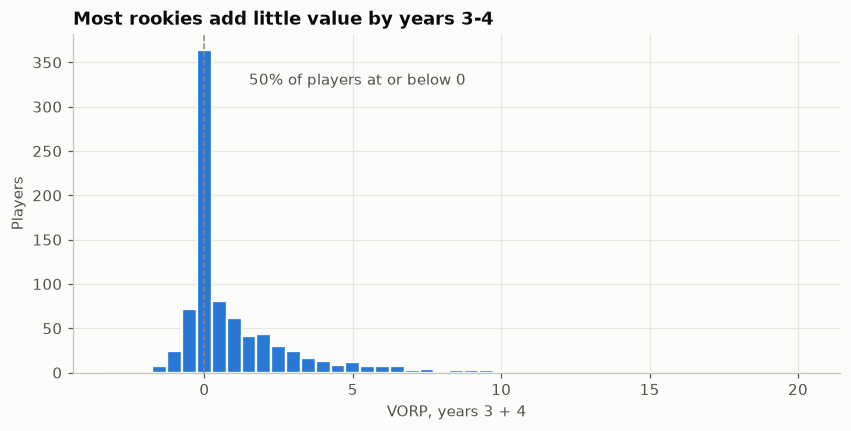

count    849.00
mean       1.08
std        2.22
min       -2.00
10%       -0.30
25%        0.00
50%        0.10
75%        1.50
90%        3.60
95%        5.40
99%        9.60
max       19.20
Name: target_vorp, dtype: float64

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(train["target_vorp"], bins=np.arange(-3.25, 20.5, 0.5),
        color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(0, color=NEUTRAL, linewidth=1, linestyle="--")
share = (train["target_vorp"] <= 0).mean()
ax.annotate(f"{share:.0%} of players at or below 0",
            xy=(1.5, ax.get_ylim()[1] * 0.85), color=INK_2)
ax.set(title="Most rookies add little value by years 3-4",
       xlabel="VORP, years 3 + 4", ylabel="Players")
plt.show()

train["target_vorp"].describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(2)

**What to look for:** a huge spike at 0 (players out of the league or barely playing)
and a long right tail (the stars). This is why the main metric is RMSE: the
expensive mistakes live in the tail.

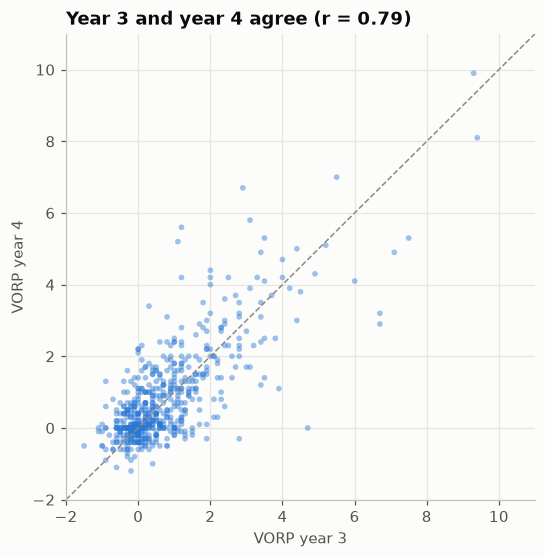

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(train["vorp_y3"], train["vorp_y4"], s=14, color=BLUE, alpha=0.45,
           edgecolor="none")
lims = [-2, 11]
ax.plot(lims, lims, color=NEUTRAL, linewidth=1, linestyle="--")
r = train[["vorp_y3", "vorp_y4"]].corr().iloc[0, 1]
ax.set(xlim=lims, ylim=lims, xlabel="VORP year 3", ylabel="VORP year 4",
       title=f"Year 3 and year 4 agree (r = {r:.2f})")
plt.show()

**What to look for:** how close the points sit to the diagonal. A high correlation
means a player's level in years 3-4 is stable, so summing both years gives a
less noisy target than either year alone.

## 2. The draft curve: what pick alone tells us

This is what the baseline will learn.

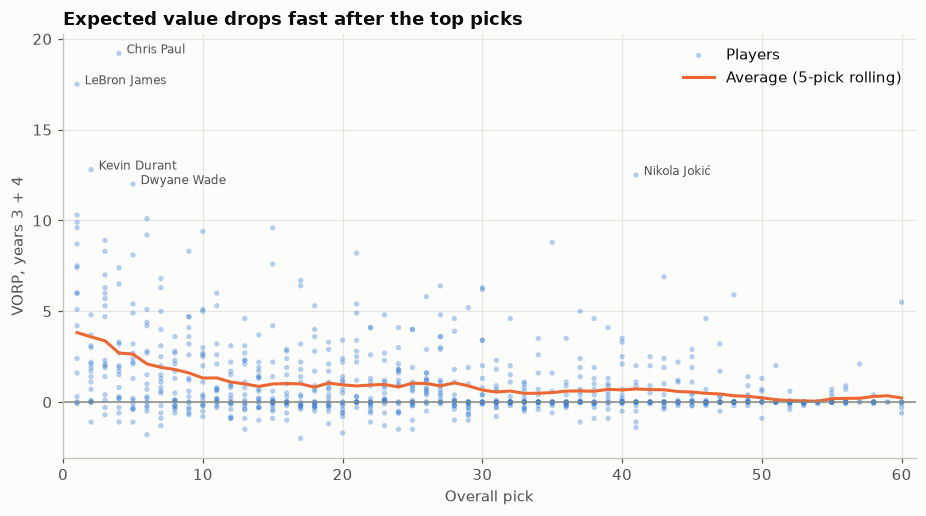

In [5]:
by_pick = train.groupby("pick")["target_vorp"].mean()
smooth = by_pick.rolling(5, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(train["pick"], train["target_vorp"], s=12, color=BLUE, alpha=0.35,
           edgecolor="none", label="Players")
ax.plot(smooth.index, smooth.values, color=ORANGE, label="Average (5-pick rolling)")
ax.axhline(0, color=NEUTRAL, linewidth=1)
for _, row in train.nlargest(5, "target_vorp").iterrows():
    ax.annotate(row["player_name"], (row["pick"], row["target_vorp"]),
                xytext=(5, 0), textcoords="offset points", fontsize=8, color=INK_2)
ax.set(title="Expected value drops fast after the top picks",
       xlabel="Overall pick", ylabel="VORP, years 3 + 4", xlim=(0, 61))
ax.legend(loc="upper right")
plt.show()

**What to look for:** the steep fall over the first ~10 picks and the flat tail
after ~30. Also the dots far above the line at late picks (steals) and the many
dots near 0 at top picks (busts): those are the cases the early games could
help with.

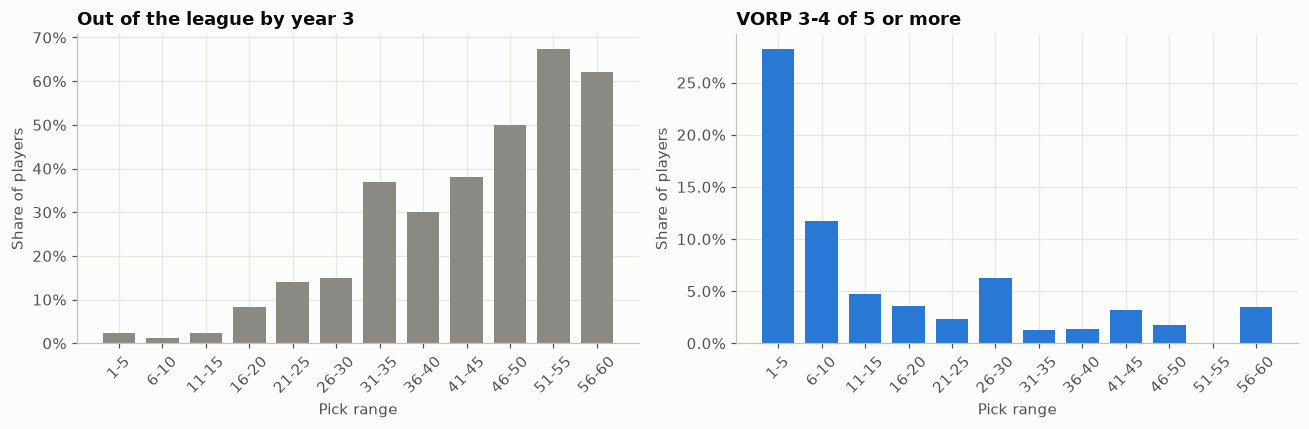

,Out of the league by year 3,VORP 3-4 of 5 or more
pick,,
1-5,0.02,0.28
6-10,0.01,0.12
11-15,0.02,0.05
16-20,0.08,0.04
21-25,0.14,0.02
26-30,0.15,0.06
31-35,0.37,0.01
36-40,0.30,0.01
41-45,0.38,0.03


In [6]:
bins = pd.cut(train["pick"], bins=range(0, 61, 5), labels=[f"{i+1}-{i+5}" for i in range(0, 60, 5)])
out_of_league = (train["mp_y3"] == 0) & (train["mp_y4"] == 0)
summary = pd.DataFrame({
    "Out of the league by year 3": out_of_league.groupby(bins, observed=True).mean(),
    "VORP 3-4 of 5 or more": (train["target_vorp"] >= 5).groupby(bins, observed=True).mean(),
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, (col, color) in zip(axes, [(summary.columns[0], NEUTRAL), (summary.columns[1], BLUE)]):
    ax.bar(summary.index, summary[col], color=color, width=0.75)
    ax.set(title=col, xlabel="Pick range", ylabel="Share of players")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
summary.round(2)

**What to look for:** where busts and good players come from. Second-rounders
leave the league much more often, but the right panel shows good players are
not only top-10 picks.

## 3. Why the era adjustment matters

League values per season, computed with the same formulas as the features.

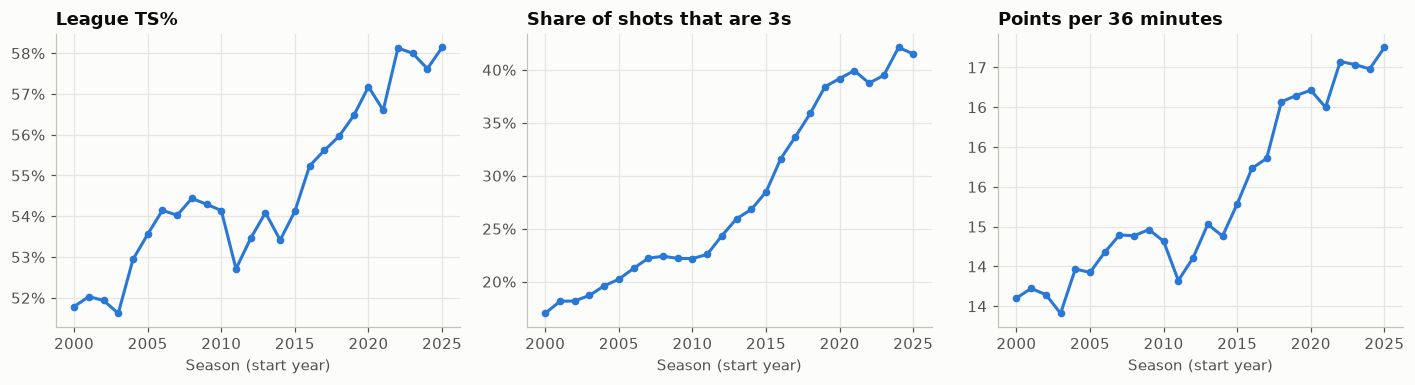

In [7]:
league = bf.num_den(bf.team_rows_as_players(), ["season"])
league_vals = pd.DataFrame({n: league[f"{n}__num"] / league[f"{n}__den"]
                            for n in bf.RATE_STATS})
start_year = league_vals.index.str[:4].astype(int)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (col, title, fmt) in zip(axes, [
        ("ts_pct", "League TS%", "{:.0%}"),
        ("fg3a_rate", "Share of shots that are 3s", "{:.0%}"),
        ("pts36", "Points per 36 minutes", "{:.0f}")]):
    ax.plot(start_year, league_vals[col], color=BLUE, marker="o", markersize=4)
    ax.set(title=title, xlabel="Season (start year)")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _, f=fmt: f.format(v)))
plt.tight_layout()
plt.show()

**What to look for:** the 3-point share more than doubled and efficiency rose a lot.
A rookie's raw TS% from 2003 and from 2016 aren't comparable, which is why the
features are relative to each season's league value.

## 4. Shrinkage in action

Raw value vs the adjusted feature. Colour = sample size (attempts).
Small samples (light dots) get pulled to the flat line of the average rookie;
big samples (dark dots) keep most of their real value.

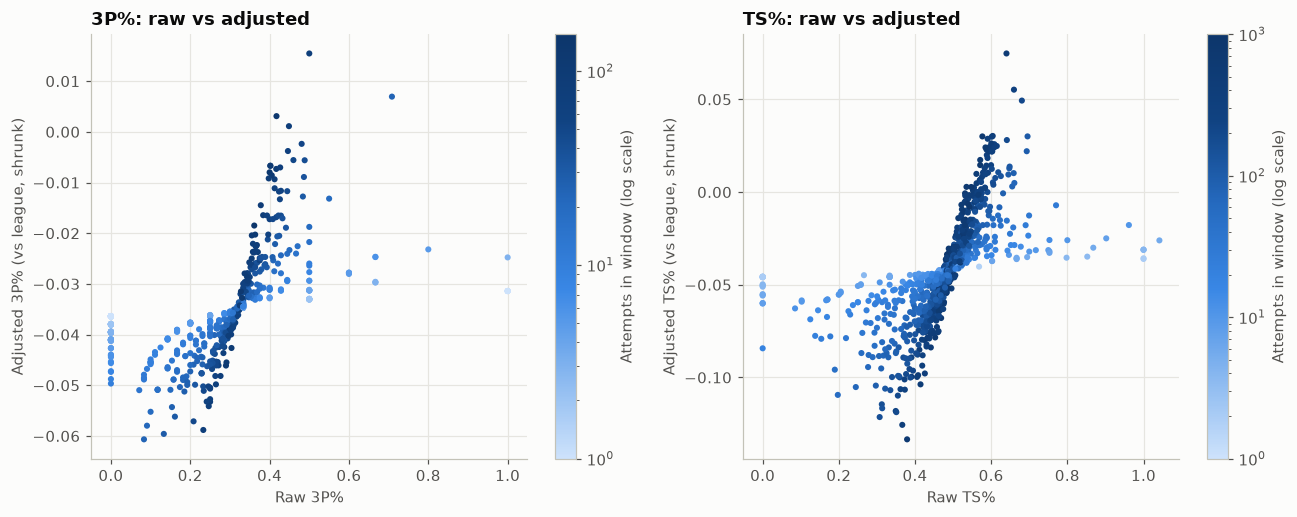

In [8]:
games = pd.read_csv(PROC / "rookie_window_games.csv")
attempts = games.groupby("player_id").agg(fg3a=("fg3a", "sum"), fga=("fga", "sum"), fta=("fta", "sum"))
attempts["tsa"] = 2 * (attempts["fga"] + 0.44 * attempts["fta"])
s = train.merge(attempts, left_on="player_id", right_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (stat, n_col, label) in zip(axes, [("fg3_pct", "fg3a", "3P%"), ("ts_pct", "tsa", "TS%")]):
    ok = s[n_col] > 0
    sc = ax.scatter(s.loc[ok, f"{stat}_raw"], s.loc[ok, stat], c=s.loc[ok, n_col],
                    cmap=SEQ_BLUE, norm=LogNorm(vmin=1, vmax=s[n_col].max()),
                    s=16, edgecolor="none")
    ax.set(title=f"{label}: raw vs adjusted", xlabel=f"Raw {label}",
           ylabel=f"Adjusted {label} (vs league, shrunk)")
    fig.colorbar(sc, ax=ax, label="Attempts in window (log scale)")
plt.tight_layout()
plt.show()

**What to look for:** the horizontal band of light dots (e.g. 1/1 or 0/2 from three)
all landing near the same adjusted value, and the dark dots spreading along a
diagonal. That is the shrinkage formula working as intended.

## 5. Feature distributions

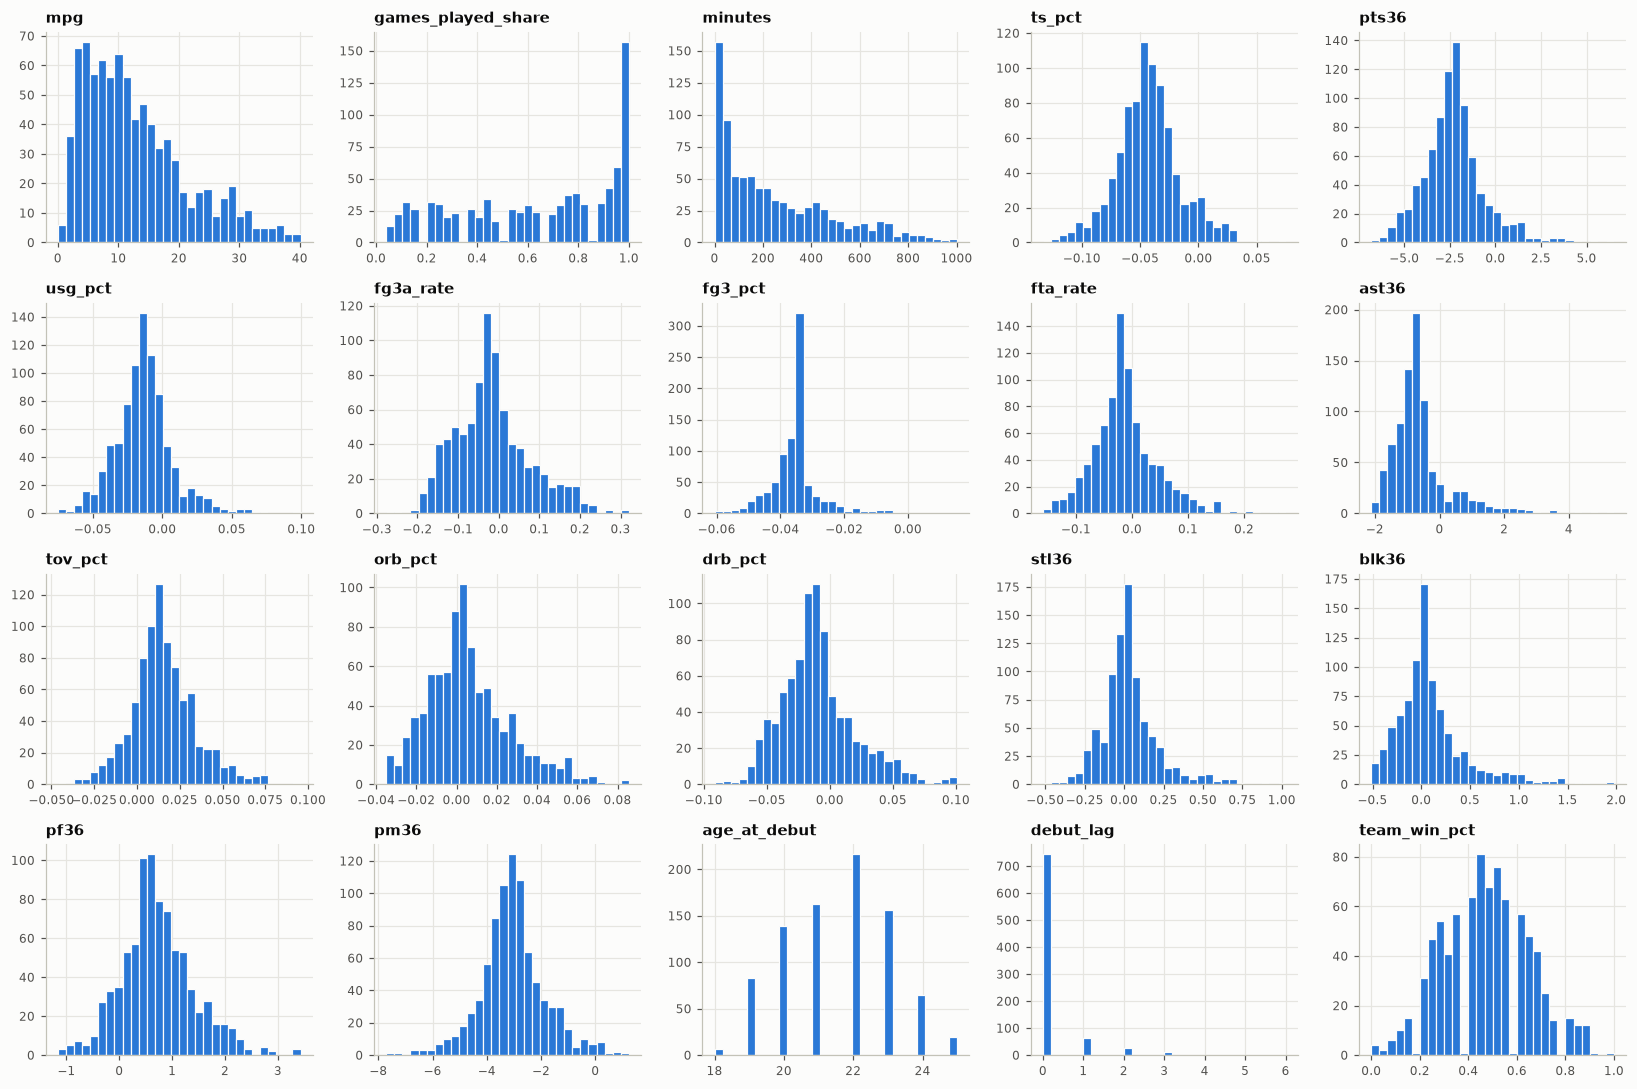

In [9]:
FEATS = ['mpg', 'games_played_share', 'minutes', 'ts_pct', 'pts36', 'usg_pct', 'fg3a_rate', 'fg3_pct', 'fta_rate', 'ast36', 'tov_pct', 'orb_pct', 'drb_pct', 'stl36', 'blk36', 'pf36', 'pm36', 'age_at_debut', 'debut_lag', 'team_win_pct']
fig, axes = plt.subplots(4, 5, figsize=(15, 10))
for ax, col in zip(axes.flat, FEATS):
    ax.hist(train[col].dropna(), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

**What to look for:** skewed features (minutes, debut lag) and spikes. Shrunk
features pile up near the rookie average because many players have small samples.

## 6. Each feature vs the target

Players are split into 10 equal-size groups (deciles) by the feature; each dot is
the group's average target. Easier to read than 900 raw dots.

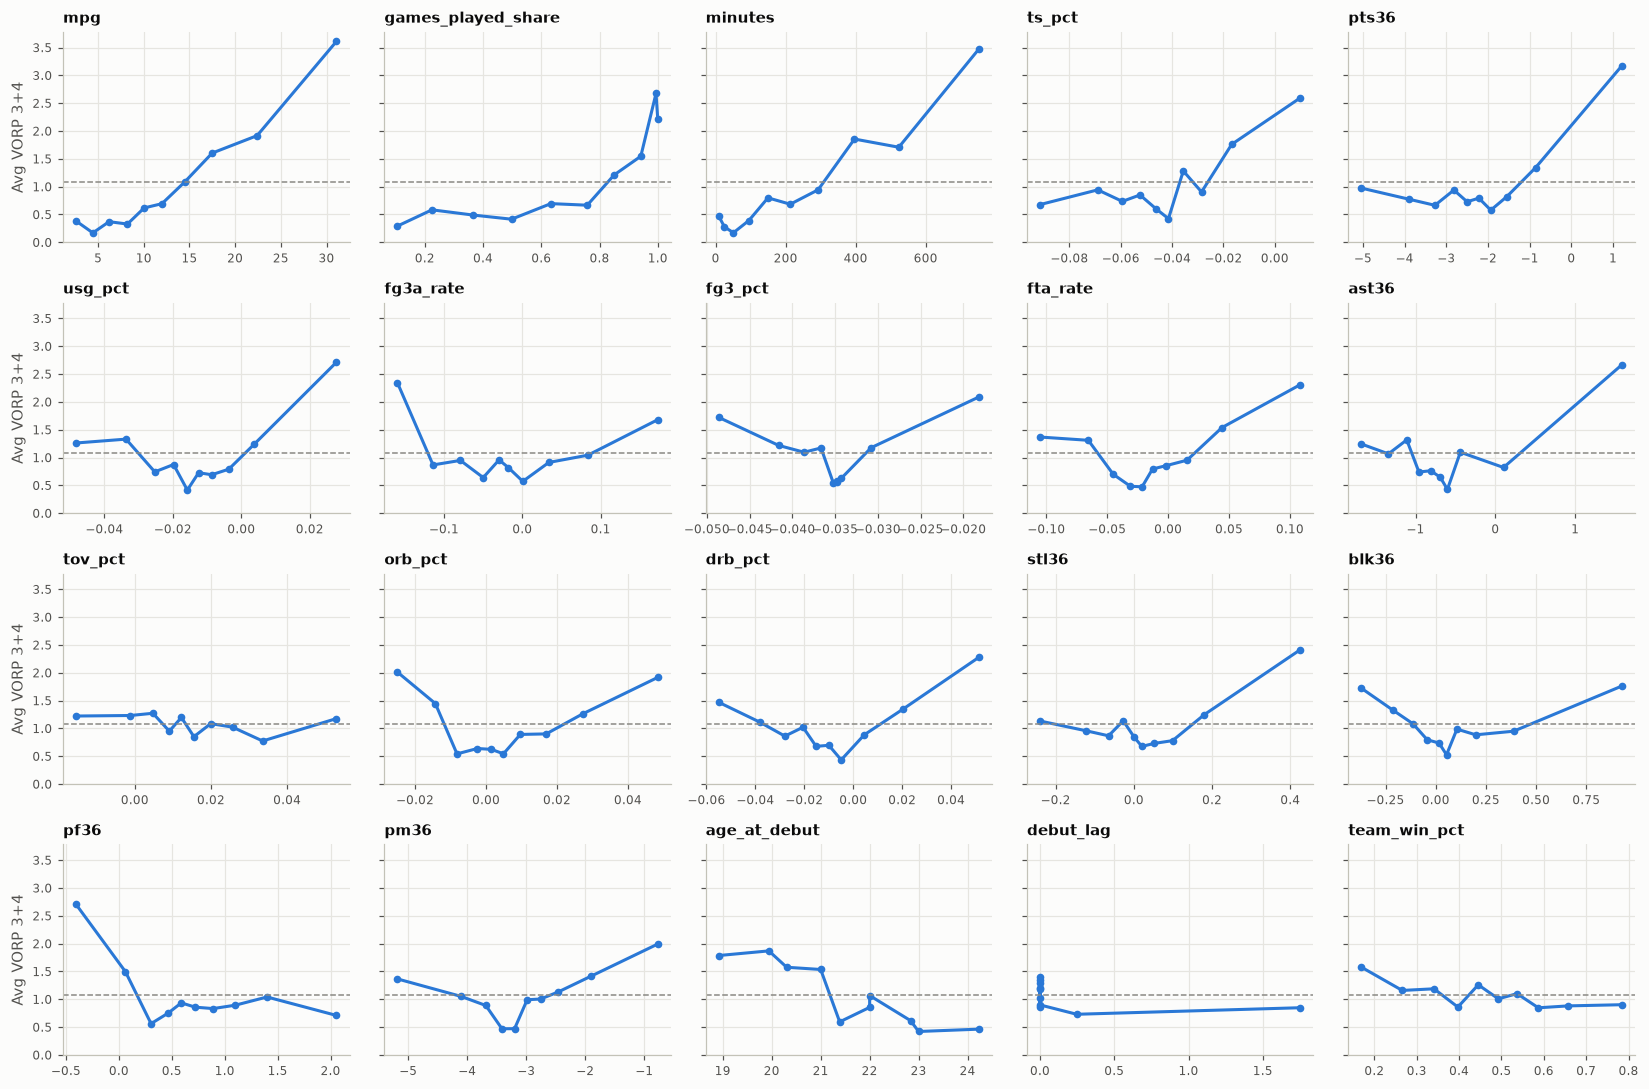

In [10]:
fig, axes = plt.subplots(4, 5, figsize=(15, 10), sharey=True)
for ax, col in zip(axes.flat, FEATS):
    d = train[[col, "target_vorp"]].dropna()
    q = pd.qcut(d[col].rank(method="first"), 10, labels=False)
    g = d.groupby(q).agg(x=(col, "mean"), y=("target_vorp", "mean"))
    ax.plot(g["x"], g["y"], color=BLUE, marker="o", markersize=4)
    ax.axhline(train["target_vorp"].mean(), color=NEUTRAL, linewidth=1, linestyle="--")
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Avg VORP 3+4")
plt.tight_layout()
plt.show()

**What to look for:** steep lines = strong signal, flat lines = little signal.
Also the *shape*: some relations aren't straight (e.g. minutes may matter mostly
at the top), which is where gradient boosting can beat a linear model.
The dashed line is the overall average.

Watch for **U shapes** (e.g. `orb_pct`, `blk36`, `fg3a_rate`, `pf36`): both ends do
better than the middle. That's most likely position: big men sit at one end,
guards and wings at the other, and good players of both types exist. A linear
model can't draw a U; gradient boosting can.

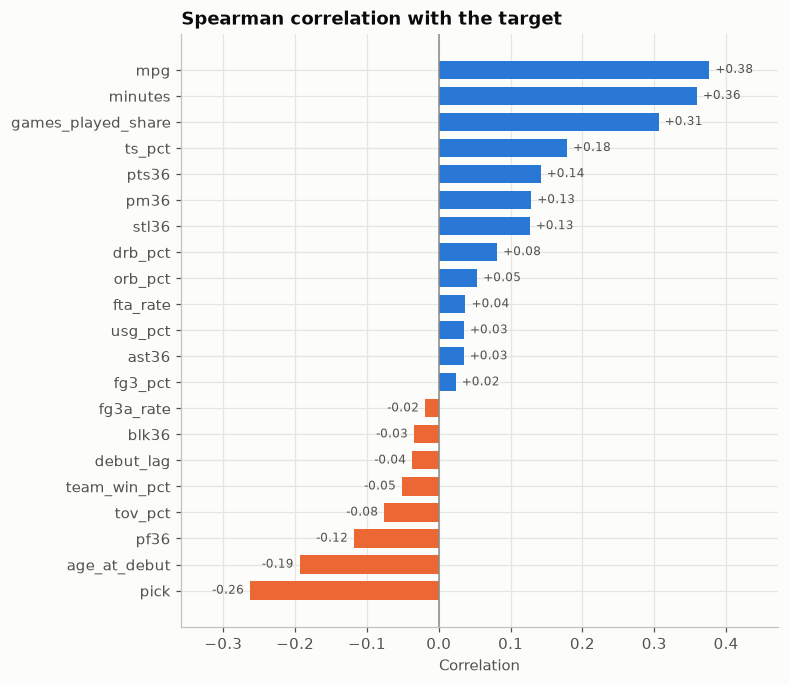

In [11]:
corr = train[FEATS + ["pick", "target_vorp"]].corr(method="spearman")
target_corr = corr["target_vorp"].drop("target_vorp").sort_values()

fig, ax = plt.subplots(figsize=(7, 7))
colors = [BLUE if v > 0 else ORANGE for v in target_corr]
ax.barh(target_corr.index, target_corr.values, color=colors, height=0.7)
ax.axvline(0, color=NEUTRAL, linewidth=1)
for y, v in enumerate(target_corr.values):
    ax.annotate(f"{v:+.2f}", (v, y), xytext=(4 if v > 0 else -4, 0),
                textcoords="offset points", va="center",
                ha="left" if v > 0 else "right", fontsize=8, color=INK_2)
ax.margins(x=0.15)
ax.set(title="Spearman correlation with the target", xlabel="Correlation")
plt.show()

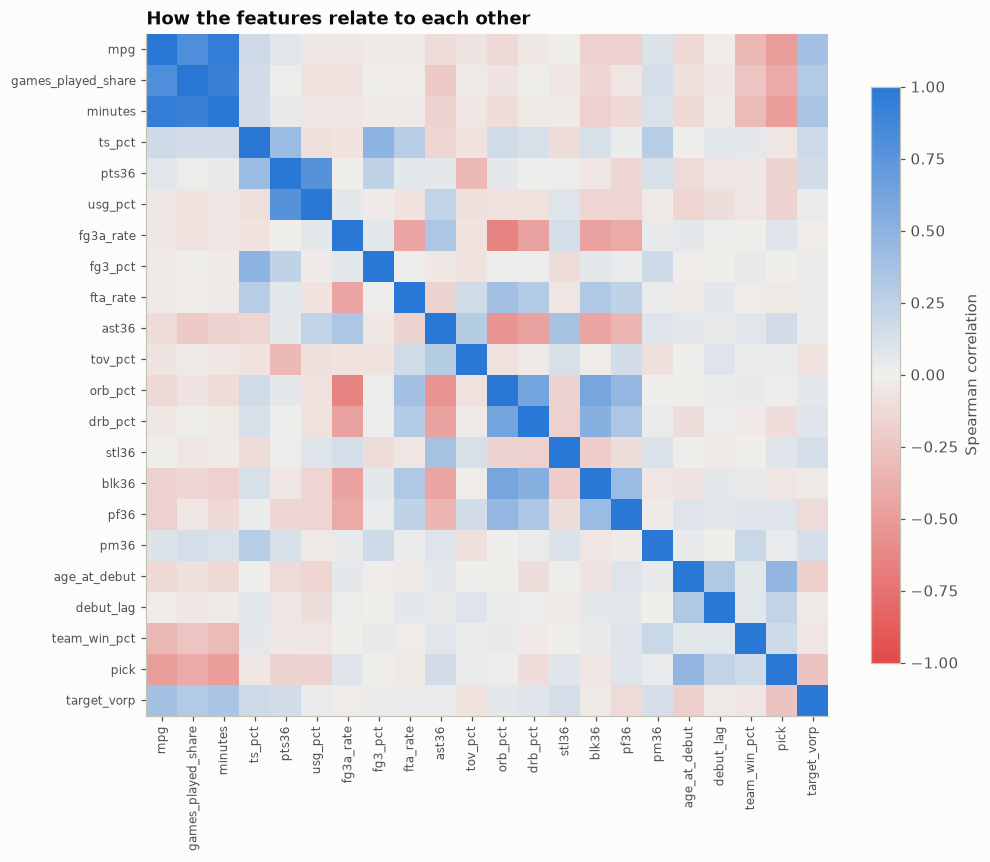

In [12]:
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Spearman correlation", shrink=0.8)
ax.set_title("How the features relate to each other")
plt.show()

**What to look for:** blocks of features that move together (e.g. minutes,
games played, usage). Strongly related features carry overlapping information,
which matters for the linear model (Ridge handles it) and for interpreting
importance later.

## 7. Preview of the key question: is there signal beyond the pick?

Early minutes correlate with the target, but top picks also get more minutes.
Two ways to separate them.

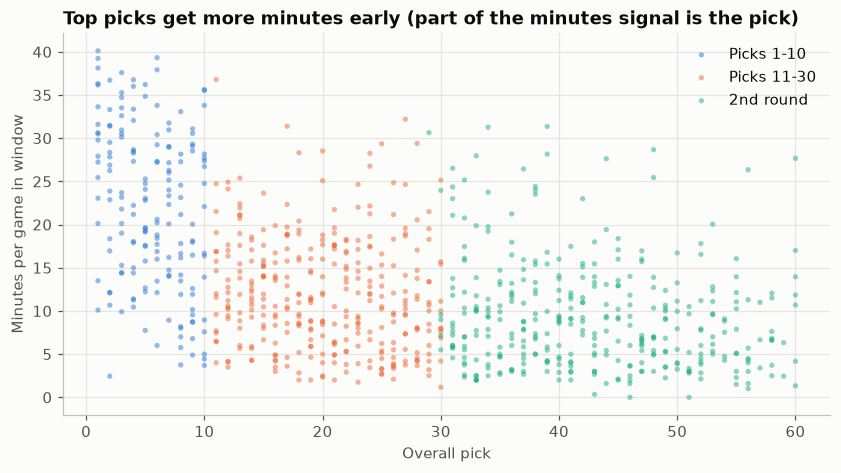

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for seg in SEGMENTS:
    d = train[train["segment"] == seg]
    ax.scatter(d["pick"], d["mpg"], s=12, alpha=0.5, color=SEG_COLORS[seg],
               edgecolor="none", label=seg)
ax.set(title="Top picks get more minutes early (part of the minutes signal is the pick)",
       xlabel="Overall pick", ylabel="Minutes per game in window")
ax.legend()
plt.show()

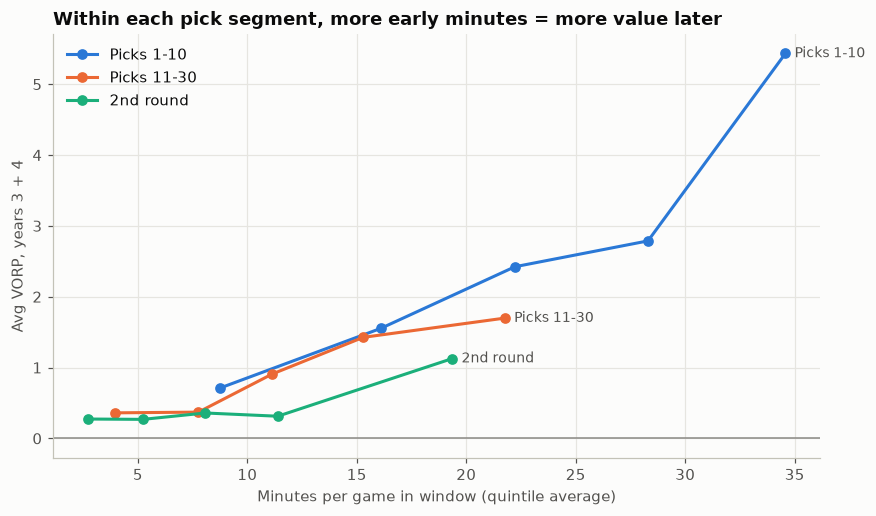

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
for seg in SEGMENTS:
    d = train[train["segment"] == seg]
    q = pd.qcut(d["mpg"].rank(method="first"), 5, labels=False)
    g = d.groupby(q).agg(x=("mpg", "mean"), y=("target_vorp", "mean"))
    ax.plot(g["x"], g["y"], color=SEG_COLORS[seg], marker="o", markersize=6, label=seg)
    ax.annotate(seg, (g["x"].iloc[-1], g["y"].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.axhline(0, color=NEUTRAL, linewidth=1)
ax.set(title="Within each pick segment, more early minutes = more value later",
       xlabel="Minutes per game in window (quintile average)", ylabel="Avg VORP, years 3 + 4")
ax.legend(loc="upper left")
plt.show()

**What to look for:** if the lines still rise *inside* each segment, minutes carry
information that the pick segment alone doesn't. Flat lines would mean the
minutes signal was only the pick in disguise.

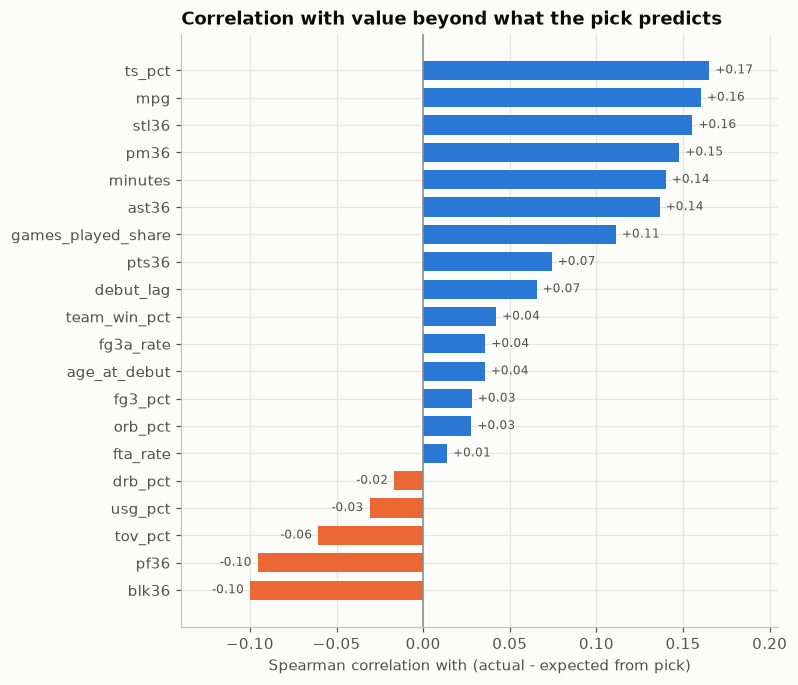

In [15]:
# Expected target from the pick alone: smooth curve on log(pick) (train only)
coef = np.polyfit(np.log(train["pick"]), train["target_vorp"], deg=2)
train["expected_from_pick"] = np.polyval(coef, np.log(train["pick"]))
train["beyond_pick"] = train["target_vorp"] - train["expected_from_pick"]

resid_corr = (train[FEATS + ["beyond_pick"]].corr(method="spearman")["beyond_pick"]
              .drop("beyond_pick").sort_values())
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(resid_corr.index, resid_corr.values,
        color=[BLUE if v > 0 else ORANGE for v in resid_corr], height=0.7)
ax.axvline(0, color=NEUTRAL, linewidth=1)
for y, v in enumerate(resid_corr.values):
    ax.annotate(f"{v:+.2f}", (v, y), xytext=(4 if v > 0 else -4, 0),
                textcoords="offset points", va="center",
                ha="left" if v > 0 else "right", fontsize=8, color=INK_2)
ax.margins(x=0.15)
ax.set(title="Correlation with value beyond what the pick predicts",
       xlabel="Spearman correlation with (actual - expected from pick)")
plt.show()

**What to look for:** this is the closest preview of the project's answer. The
bars show which early-game features explain *over/under-performance relative to
draft slot*. Long bars here are the features most likely to beat the baseline.

In [16]:
cols = ["player_name", "draft_year", "pick", "age_at_debut", "mpg", "ts_pct",
        "target_vorp", "expected_from_pick", "beyond_pick"]
print("Biggest over-performers vs their pick")
display(train.nlargest(10, "beyond_pick")[cols].round(2))
print("Biggest under-performers vs their pick")
display(train.nsmallest(10, "beyond_pick")[cols].round(2))

Biggest over-performers vs their pick


,player_name,draft_year,pick,age_at_debut,mpg,ts_pct,target_vorp,expected_from_pick,beyond_pick
239,Chris Paul,2005,4,20.0,36.76,-0.01,19.2,2.61,16.59
143,LeBron James,2003,1,19.0,40.12,-0.03,17.5,5.03,12.47
737,Nikola Jokić,2014,41,20.0,17.48,0.02,12.5,0.51,11.99
147,Dwyane Wade,2003,5,22.0,36.22,-0.03,12.0,2.30,9.70
344,Kevin Durant,2007,2,19.0,33.32,-0.04,12.8,3.71,9.09
661,Giannis Antetokounmpo,2013,15,19.0,19.40,-0.00,9.6,1.11,8.49
625,Draymond Green,2012,35,22.0,14.72,-0.11,8.8,0.57,8.23
296,Brandon Roy,2006,6,22.0,27.20,-0.05,10.1,2.07,8.03
498,Paul George,2010,10,20.0,16.38,-0.06,9.4,1.49,7.91
311,Rajon Rondo,2006,21,20.0,15.43,-0.07,8.2,0.86,7.34


Biggest under-performers vs their pick


,player_name,draft_year,pick,age_at_debut,mpg,ts_pct,target_vorp,expected_from_pick,beyond_pick
698,Andrew Wiggins,2014,1,19.0,30.64,-0.06,-0.1,5.03,-5.13
343,Greg Oden,2007,1,21.0,23.05,-0.01,0.0,5.03,-5.03
647,Anthony Bennett,2013,1,20.0,10.10,-0.12,0.0,5.03,-5.03
490,Evan Turner,2010,2,22.0,23.88,-0.06,-1.1,3.71,-4.81
50,Kwame Brown,2001,1,19.0,13.50,-0.06,0.3,5.03,-4.73
348,Yi Jianlian,2007,6,20.0,27.32,-0.02,-1.8,2.07,-3.87
293,Adam Morrison,2006,3,22.0,33.52,-0.08,-0.7,3.04,-3.74
595,Dion Waiters,2012,4,21.0,32.06,-0.06,-1.1,2.61,-3.71
100,Jay Williams,2002,2,21.0,31.40,-0.07,0.0,3.71,-3.71
440,Hasheem Thabeet,2009,2,22.0,10.67,-0.02,0.0,3.71,-3.71


**What to look for:** did the steals already show something in their first games
(high minutes, good efficiency)? And did the busts look bad early, or did they
look fine and fall off later (which no early-game model can catch)?